In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.colors import to_rgba
from matplotlib.patches import Patch

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'uni_agent').is_dir() and (p / 'meta/plot').is_dir())
PLOT = REPO / 'meta/plot'
DATASETS = {
    'SWE-bench Verified': PLOT / 'data/verified_characterization_1host_20261019.csv',
    'SWE-bench Pro': PLOT / 'data/pro_characterization_1host_20261015.csv',
}
FIGURES = PLOT / 'figure'
FIGURES.mkdir(parents=True, exist_ok=True)

sns.set_style('ticks')
sns.set_style({'font.family': ['Roboto', 'DejaVu Sans'], 'font.size': 12})
sns.set_context('paper', font_scale=2,
                rc={'lines.linewidth': 3, 'lines.markersize': 10})
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'legend.frameon': False, 'pdf.fonttype': 42, 'ps.fonttype': 42,
    'svg.fonttype': 'none',
})
PALETTE = {
    'blue_main': '#0F4D92', 'blue_secondary': '#3775BA',
    'green_3': '#8BCF8B', 'green_dark': '#397A39',
    'red_strong': '#B64342', 'neutral': '#CFCECE',
    'teal': '#42949E', 'violet': '#9A4D8E',
}

In [2]:
frames = {}
expected_usable = {
    'SWE-bench Verified': [1024, 1024, 1023, 1024],
    'SWE-bench Pro': [1024, 1020, 1020, 319],
}
for benchmark, path in DATASETS.items():
    provenance = json.loads(path.with_suffix('.provenance.json').read_text())
    assert hashlib.sha256(path.read_bytes()).hexdigest() == provenance['sha256']
    assert provenance['runtime_count'] == 1
    assert provenance['benchmark'] == {
        'SWE-bench Verified': 'swebench-verified', 'SWE-bench Pro': 'swebench-pro',
    }[benchmark]
    data = pd.read_csv(path).sort_values('concurrency_episodes').reset_index(drop=True)
    assert data.concurrency_episodes.tolist() == [64, 128, 256, 512]
    assert data.terminal_attempts.eq(1024).all()
    assert (data.verified_attempts + data.incomplete_verifications).eq(1024).all()
    assert data.usable_trajectories.tolist() == expected_usable[benchmark]
    data['usable_samples_per_minute'] = (
        data.usable_trajectories * 60 / data.rollout_wall_seconds
    )
    for metric in ('sandbox_cpu', 'sandbox_ram'):
        assert data[f'{metric}_mean_pct'].between(0, 100).all()
        assert data[f'{metric}_peak_5s_pct'].between(0, 100).all()
        assert (data[f'{metric}_peak_5s_pct'] >= data[f'{metric}_mean_pct']).all()
    assert data.client_active_requests_mean.ge(0).all()
    assert (data.client_active_requests_peak >= data.client_active_requests_mean).all()
    frames[benchmark] = data

summary = pd.concat({
    benchmark: data.rename(columns={
        'concurrency_episodes': 'Concurrency',
        'usable_trajectories': 'Usable samples',
        'usable_samples_per_minute': 'Usable samples / min',
        'client_active_requests_mean': 'Client calls in flight (mean)',
        'sandbox_cpu_mean_pct': 'CPU mean (%)',
        'sandbox_cpu_peak_5s_pct': 'CPU peak ~5 s (%)',
        'sandbox_ram_mean_pct': 'Host RAM mean (%)',
        'sandbox_ram_peak_5s_pct': 'Host RAM peak ~5 s (%)',
    }).set_index('Concurrency')[[
        'Usable samples', 'Usable samples / min', 'Client calls in flight (mean)',
        'CPU mean (%)', 'CPU peak ~5 s (%)',
        'Host RAM mean (%)', 'Host RAM peak ~5 s (%)',
    ]]
    for benchmark, data in frames.items()
}, names=['Benchmark'])
display(summary.round(2))


Usable samples  Usable samples / min  \
Benchmark          Concurrency                                         
SWE-bench Verified 64                     1024                 50.42   
                   128                    1024                 70.79   
                   256                    1023                 83.50   
                   512                    1024                 81.12   
SWE-bench Pro      64                     1024                 28.62   
                   128                    1020                 56.76   
                   256                    1020                 79.74   
                   512                     319                 24.01   

                                Client calls in flight (mean)  CPU mean (%)  \
Benchmark          Concurrency                                                
SWE-bench Verified 64                                    9.79         30.40   
                   128                                  18.49         58.65   
                   256                                  32.86         83.13   
                   512                                  52.14         84.05   
SWE-bench Pro      64                                    2.84         40.16   
                   128                                   7.46         88.00   
                   256                                  15.05         90.69   
                   512                                 115.53         81.43   

                                CPU peak ~5 s (%)  Host RAM mean (%)  \
Benchmark          Concurrency                                         
SWE-bench Verified 64                       56.62               8.04   
                   128                      97.69              13.51   
                   256                      99.88              26.47   
                   512                      99.96              46.40   
SWE-bench Pro      64                       68.40              10.43   
                   128                      99.91              21.64   
                   256                      99.95              32.37   
                   512                      99.97              38.09   

                                Host RAM peak ~5 s (%)  
Benchmark          Concurrency                          
SWE-bench Verified 64                            12.12  
                   128                           19.80  
                   256                           39.62  
                   512                           75.37  
SWE-bench Pro      64                            20.38  
                   128                           31.04  
                   256                           48.81  
                   512                           55.93

**One sandbox host per row; historical Pro limitations**

The top row uses the completed October 19 one-host **SWE-bench Verified** sweep.
The bottom row uses the only full one-host **SWE-bench Pro** sweep, from October 15.
That Pro sweep used an unintended **180-second verifier command cap at every concurrency**;
its **C=512 point also suffered an engine failure**, leaving only 319 usable trajectories.
The Pro row describes that historical run and is not a clean matched comparison with Verified.
A newer clean Pro C=128 run exists but is not spliced into this older sweep.

- Both rows use one 96-vCPU AWS sandbox host; inference uses two TP4 replicas on eight GPUs.
  The measured window runs from `model_ready_at` to `model_ready_at + rollout_wall_seconds`.
  Startup and cleanup are excluded; tool execution and verification waits remain included.
- Usable throughput is stored usable trajectories divided by rollout seconds, multiplied by 60.
  It is distinct from completed reward-verification throughput. Verified usable counts are
  **1,024 / 1,024 / 1,023 / 1,024**; historical Pro counts are **1,024 / 1,020 / 1,020 / 319**.
- The request bars show **client model calls in flight**, reconstructed from matched model-call
  begin and end/error timestamps and integrated over the rollout window across both replicas.
  They include queued/waiting calls and use the right count axis. This common metric is available
  for both sweeps; actual vLLM running-request telemetry is unavailable for historical Pro.
  In particular, Pro C=512 includes calls awaiting errors/timeouts during the engine failure.
- CPU uses all **96 sandbox vCPUs**, excludes idle/I/O wait, and counts VM guest ticks once.
  Host RAM is **100 × (MemTotal − MemAvailable) / MemTotal**, including OS/runtime/VM memory;
  it is distinct from KV-cache utilization or anonymous process memory.
- CPU/RAM means are duration-weighted over available host telemetry. Peaks are maxima of
  complete, aligned five-second bins. Solid bars end at the mean; hatched upper segments reach
  the peak. Both segments have identical width and no border stroke.
- These are observed sampled peaks, not confidence intervals. There is one observation per point.

Frozen `.provenance.json` metadata retains source hashes, exact rollout windows, aggregation rules,
coverage, and run limitations. Rendering uses only local frozen inputs.


Saved: meta/plot/figure/concurrency_characterization_1host.png, meta/plot/figure/concurrency_characterization_1host.pdf, meta/plot/figure/concurrency_characterization_1host.svg


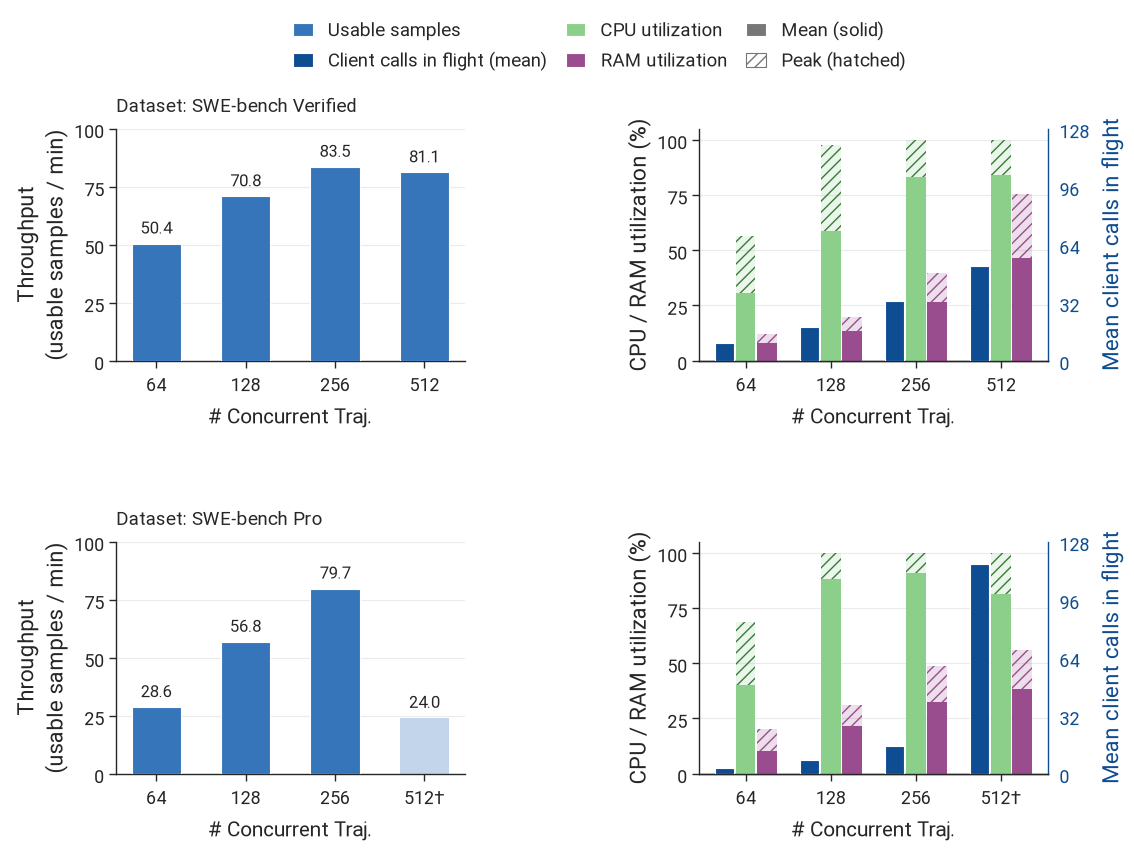

In [4]:
def mean_peak_bar(axis, positions, means, peaks, color, edgecolor=None):
    """One bar: solid base to mean, hatched extension from mean to peak."""
    edgecolor = edgecolor or color
    axis.bar(positions, means, width=.23, color=color, linewidth=0, zorder=3)
    axis.bar(positions, peaks - means, bottom=means, width=.23,
             facecolor=to_rgba(color, .18), edgecolor=edgecolor,
             hatch='///', linewidth=0, zorder=3)


def draw_characterization(datasets):
    fig, axes = plt.subplots(2, 2, figsize=(11.8, 8.6))
    fig.subplots_adjust(left=.09, right=.88, bottom=.09, top=.84,
                        wspace=.67, hspace=.78)
    for row, (benchmark, data) in enumerate(datasets.items()):
        throughput, resources = axes[row]
        x = np.arange(len(data))
        requests = resources.twinx()
        requests.patch.set_visible(False)
        historical = benchmark == 'SWE-bench Pro'
        labels = [str(value) + ('†' if historical and value == 512 else '')
                  for value in data.concurrency_episodes]

        usable = throughput.bar(
            x, data.usable_samples_per_minute, width=.55,
            color=PALETTE['blue_secondary'], zorder=3)
        throughput.bar_label(
            usable, labels=[f'{value:.1f}' for value in data.usable_samples_per_minute],
            padding=4, fontsize=12)
        title = f'Dataset: {benchmark}'
        if historical:
            usable[-1].set_facecolor(to_rgba(PALETTE['blue_secondary'], .3))
            usable[-1].set_edgecolor(PALETTE['blue_secondary'])
            usable[-1].set_linewidth(0)
        throughput.set_title(title, loc='left', fontsize=13.5, pad=12)
        throughput.set_ylabel('Throughput\n(usable samples / min)', fontsize=16)
        throughput.set_ylim(0, 100)
        throughput.set_yticks([0, 25, 50, 75, 100])

        requests.bar(
            x - .25, data.client_active_requests_mean, width=.23,
            color=PALETTE['blue_main'], zorder=3)
        mean_peak_bar(resources, x, data.sandbox_cpu_mean_pct, data.sandbox_cpu_peak_5s_pct,
                      PALETTE['green_3'], PALETTE['green_dark'])
        mean_peak_bar(resources, x + .25, data.sandbox_ram_mean_pct, data.sandbox_ram_peak_5s_pct,
                      PALETTE['violet'])
        resources.set_ylabel('CPU / RAM utilization (%)', fontsize=16)
        resources.set_ylim(0, 105)
        resources.set_yticks([0, 25, 50, 75, 100])
        requests.set_ylabel('Mean client calls in flight', fontsize=16,
                            color=PALETTE['blue_main'])
        requests.set_ylim(0, 128)
        requests.set_yticks([0, 32, 64, 96, 128])
        requests.tick_params(axis='y', colors=PALETTE['blue_main'])
        requests.spines['right'].set_color(PALETTE['blue_main'])

        for axis in (throughput, resources):
            axis.set_xticks(x, labels)
            axis.set_xlabel('# Concurrent Traj.', fontsize=15)
            axis.tick_params(labelsize=13)
            axis.grid(axis='y', color=PALETTE['neutral'], linewidth=.8, alpha=.4, zorder=0)
            axis.set_axisbelow(True)
            sns.despine(ax=axis)
        requests.tick_params(labelsize=13)
        sns.despine(ax=requests, left=True, right=False)

    handles = [
        Patch(facecolor=PALETTE['blue_secondary'], label='Usable samples'),
        Patch(facecolor=PALETTE['blue_main'], label='Client calls in flight (mean)'),
        Patch(facecolor=PALETTE['green_3'], label='CPU utilization'),
        Patch(facecolor=PALETTE['violet'], label='RAM utilization'),
        Patch(facecolor='#777777', label='Mean (solid)'),
        Patch(facecolor='white', edgecolor='#777777', hatch='///', label='Peak (hatched)'),
    ]
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(.5, .99),
               ncol=3, fontsize=13.5, columnspacing=1, handlelength=1.05,
               labelspacing=.3, frameon=False)
    return fig


figure = draw_characterization(frames)
output = FIGURES / 'concurrency_characterization_1host'
for extension in ('png', 'pdf', 'svg'):
    figure.savefig(output.with_suffix('.' + extension), dpi=300,
                   facecolor='white', bbox_inches='tight')
print('Saved:', ', '.join(str(output.with_suffix('.' + ext).relative_to(REPO))
                         for ext in ('png', 'pdf', 'svg')))